# Diabetes Classification — Reproducible ML Research Pipeline

**Author:** Val  
**Purpose:** Educational research and portfolio demonstration, **not medical diagnosis or clinical decision support**.

**What's improved:** model selection using only training data; validation-only threshold choice; categorical-safe class rebalancing; one final holdout evaluation; probability calibration diagnostics; reproducible exports; explainability and slice checks.

**Data note:** HbA1c and blood glucose are themselves clinical tests used in diabetes assessment. This project predicts *labels in the source dataset*, not future disease onset. Strong test performance does not establish clinical validity. The previous `report.pdf` describes an older experiment and should not be used to claim results from this revised notebook until it is rerun and revised.

**Execution:** Place `diabetes_prediction_dataset.csv` in the `data/` folder next to this notebook (or set `DATA_PATH` in the loading cell), then **Run All**. The dataset itself is not included in this download. Keep real patient information out of GitHub.

In [15]:
from pathlib import Path
import json
import platform
import warnings
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve, ConfusionMatrixDisplay,
    PrecisionRecallDisplay, RocCurveDisplay,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42
TEST_SIZE = 0.20
VALIDATION_SIZE_WITHIN_TRAIN = 0.20
CV_FOLDS = 3  # Set to 5 for the full benchmark (slower).
TARGET_COLUMN = "diabetes"
RECALL_TARGET = 0.90  # Research-only illustrative sensitivity target, NOT a clinical cutoff.
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print("Python:", platform.python_version())
print("Ready. Results will be written to:", OUTPUT_DIR.resolve())

Python: 3.14.6
Ready. Results will be written to: C:\Users\User\PyCharmMiscProject\diabetes prediction model\output


## 1. Load data and validate schema

No machine-specific Windows path. The source dataset is intentionally not bundled. The input must contain the expected columns. This check catches incomplete or incorrectly named datasets early.

In [16]:
DATA_PATH = Path("data/diabetes_prediction_dataset.csv")
if not DATA_PATH.exists():
    alternatives = [
        Path("diabetes_prediction_dataset.csv"),
        Path("csv file/diabetes_prediction_dataset.csv"),
    ]
    DATA_PATH = next((p for p in alternatives if p.is_file()), DATA_PATH)
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        "Dataset missing. Download it from the original data source and place "
        "diabetes_prediction_dataset.csv in the data/ folder beside this notebook. "
        f"Looked for: {DATA_PATH.resolve()}"
    )

df = pd.read_csv(DATA_PATH)
NUMERIC_FEATURES = ["age", "hypertension", "heart_disease", "bmi", "HbA1c_level", "blood_glucose_level"]
CATEGORICAL_FEATURES = ["gender", "smoking_history"]
REQUIRED_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES + [TARGET_COLUMN]
missing_columns = sorted(set(REQUIRED_COLUMNS) - set(df.columns))
if missing_columns:
    raise ValueError(f"Missing required dataset columns: {missing_columns}")
print(f"Loaded {len(df):,} records from {DATA_PATH}")
display(df.head())

Loaded 100,000 records from csv file\diabetes_prediction_dataset.csv


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


## 2. Quality audit and basic cleaning

Duplicated *rows* are removed before splitting only to match the original project. Identical rows do not necessarily mean the same patient. Without a patient identifier, patient-level leakage cannot be excluded; this limitation must be disclosed. No learned imputation, resampling or scaling occurs before splitting.

In [17]:
print("Data types:")
display(df.dtypes.to_frame("dtype"))
print("Missing values:")
display(df[REQUIRED_COLUMNS].isna().sum().to_frame("count"))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Unique categorical values:")
for name in CATEGORICAL_FEATURES:
    print(name, sorted(df[name].dropna().astype(str).unique().tolist()))

raw_n = len(df)
df = df.drop_duplicates().reset_index(drop=True)
for col in NUMERIC_FEATURES + [TARGET_COLUMN]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
df = df.loc[df[TARGET_COLUMN].isin([0, 1])].copy()
df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(int)
for binary_col in ["hypertension", "heart_disease"]:
    invalid = df[binary_col].dropna().loc[lambda x: ~x.isin([0, 1])]
    if not invalid.empty:
        raise ValueError(f"Invalid binary input in {binary_col}: {invalid.unique()}")
if df[TARGET_COLUMN].nunique() != 2:
    raise ValueError("Both classes must be present for binary classification.")
print(f"Removed {raw_n - len(df):,} exact duplicates / invalid-target records; remaining {len(df):,}")
display(df[TARGET_COLUMN].value_counts().rename(index={0:"No diabetes",1:"Diabetes"}).to_frame("records"))

Data types:


,dtype
gender,object
age,float64
hypertension,int64
heart_disease,int64
smoking_history,object
bmi,float64
HbA1c_level,float64
blood_glucose_level,int64
diabetes,int64


Missing values:


,count
age,0
hypertension,0
heart_disease,0
bmi,0
HbA1c_level,0
blood_glucose_level,0
gender,0
smoking_history,0
diabetes,0


Exact duplicate rows: 3854
Unique categorical values:
gender ['Female', 'Male', 'Other']
smoking_history ['No Info', 'current', 'ever', 'former', 'never', 'not current']
Removed 3,854 exact duplicates / invalid-target records; remaining 96,146


,records
diabetes,
No diabetes,87664
Diabetes,8482


## 3. Exploratory data analysis

These charts are descriptive. Correlation and SHAP explanations cannot establish medical causation.

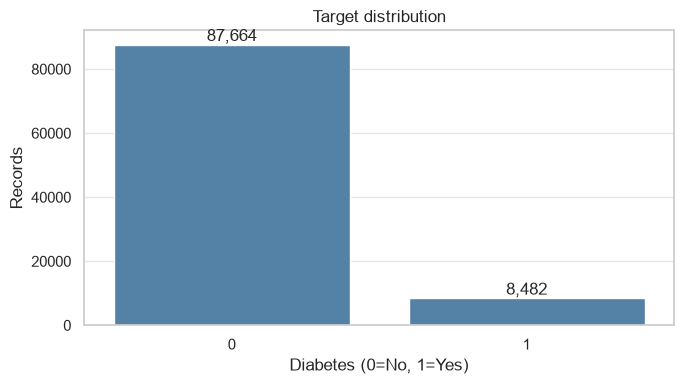

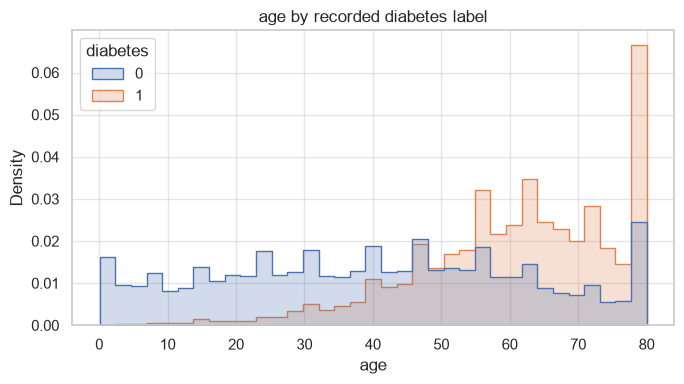

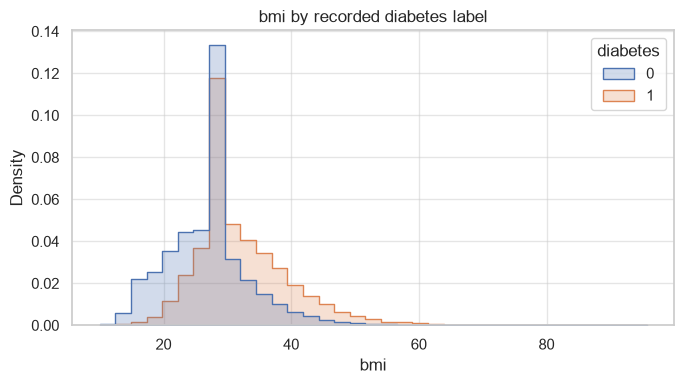

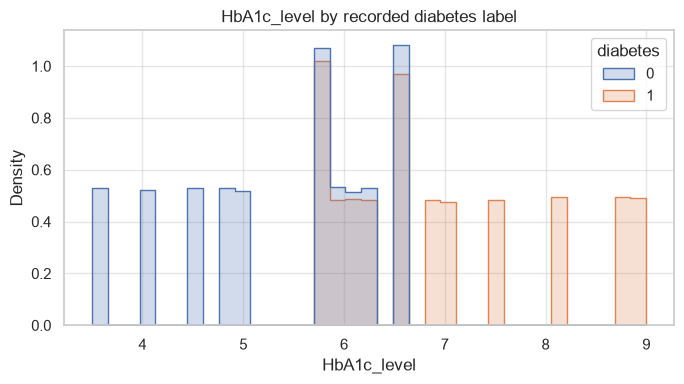

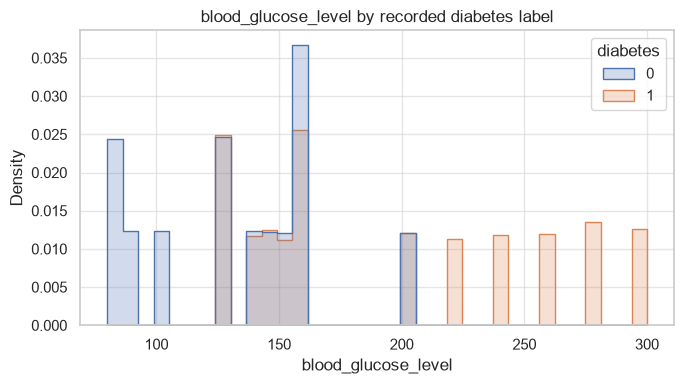

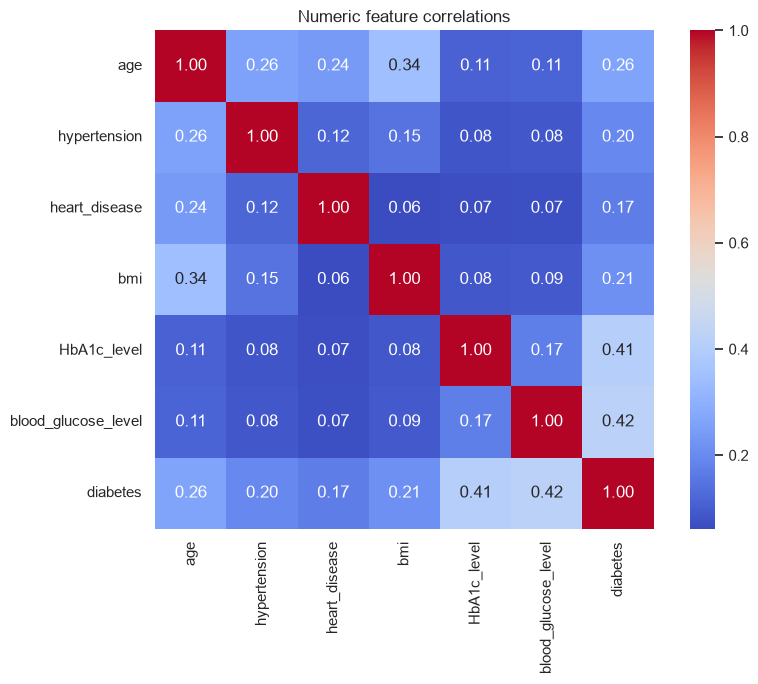

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.countplot(data=df, x=TARGET_COLUMN, color="steelblue", ax=ax)
for patch in ax.patches:
    height = patch.get_height()
    ax.annotate(f"{height:,.0f}", (patch.get_x() + patch.get_width()/2, height),
                ha="center", va="bottom")
ax.set(xlabel="Diabetes (0=No, 1=Yes)", ylabel="Records", title="Target distribution")
plt.tight_layout(); plt.show()

for feature in ["age", "bmi", "HbA1c_level", "blood_glucose_level"]:
    fig, ax = plt.subplots(figsize=(7, 4))
    sns.histplot(data=df, x=feature, hue=TARGET_COLUMN, stat="density",
                 common_norm=False, bins=35, element="step", ax=ax)
    ax.set_title(f"{feature} by recorded diabetes label")
    plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(df[NUMERIC_FEATURES + [TARGET_COLUMN]].corr(), annot=True,
            fmt=".2f", cmap="coolwarm", square=True, ax=ax)
ax.set_title("Numeric feature correlations")
plt.tight_layout(); plt.show()

## 4. Lock the holdout; create development and validation splits

The 20% **test set is not touched for model selection or threshold choice**. Within the remaining 80%, a validation split is reserved to select a decision threshold. CV compares models using only the development subset. The full training partition is used for the final refit.

In [19]:
X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES].copy()
y = df[TARGET_COLUMN].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE
)
X_dev, X_val, y_dev, y_val = train_test_split(
    X_train, y_train, test_size=VALIDATION_SIZE_WITHIN_TRAIN,
    stratify=y_train, random_state=RANDOM_STATE
)
for name, subset_y in [("Development",y_dev),("Validation",y_val),("Train (combined)",y_train),("Final holdout",y_test)]:
    print(f"{name}: {len(subset_y):,} rows | positive class: {subset_y.mean():.2%}")

Development: 61,532 rows | positive class: 8.82%
Validation: 15,384 rows | positive class: 8.82%
Train (combined): 76,916 rows | positive class: 8.82%
Final holdout: 19,230 rows | positive class: 8.82%


## 5. Leakage-safe preprocessing and class imbalance

All missing-value imputation and scaling are fitted inside CV folds. We use **RandomOverSampler on the preprocessed training-fold rows**, instead of standard SMOTE: standard SMOTE applied after one-hot encoding can create fractional values for categorical indicators. Oversampling is applied **only** during `.fit()`, never to validation or test records. Compare with no resampling / class weights in future experiments; oversampling is not guaranteed to improve calibration.

In [20]:
num_transform = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_transform = ImbPipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_transform, NUMERIC_FEATURES),
    ("cat", cat_transform, CATEGORICAL_FEATURES),
], verbose_feature_names_out=False)

def make_pipeline(estimator):
    return ImbPipeline([
        ("preprocessor", clone(preprocessor)),
        ("oversample", RandomOverSampler(random_state=RANDOM_STATE)),
        ("model", clone(estimator)),
    ])

## 6. Candidate models and stratified CV

We compare the **same three** candidate estimators with the same development rows and CV folds: Logistic Regression, Random Forest and XGBoost. The original notebook also included SVC trained on a smaller sample, making its comparison unequal. SVC can be added later using an explicitly documented compute budget. ROC-AUC is the predefined *ranking criterion*; recall, PR-AUC and calibration are also reported. `CV_FOLDS = 3` is a faster portfolio default (change to 5 for the full benchmark).

In [21]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2_000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=250, min_samples_split=5, min_samples_leaf=2,
        n_jobs=2, random_state=RANDOM_STATE),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=4, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        objective="binary:logistic", eval_metric="logloss",
        n_jobs=2, random_state=RANDOM_STATE),
}
pipelines = {name: make_pipeline(estimator) for name, estimator in models.items()}
cv = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy", "precision": "precision", "recall": "recall",
    "f1": "f1", "roc_auc": "roc_auc", "average_precision": "average_precision",
}
cv_rows = []
for model_name, candidate in pipelines.items():
    print(f"Cross-validating: {model_name}")
    scores = cross_validate(candidate, X_dev, y_dev, cv=cv,
                            scoring=scoring, n_jobs=1, error_score="raise")
    cv_rows.append({
        "Model": model_name,
        **{f"{metric} Mean": float(scores[f"test_{metric}"].mean()) for metric in scoring},
        "ROC-AUC SD": float(scores["test_roc_auc"].std()),
        "Fit Time Mean (s)": float(scores["fit_time"].mean()),
    })
cv_results = pd.DataFrame(cv_rows).sort_values(
    "roc_auc Mean", ascending=False).reset_index(drop=True)
display(cv_results.round(4))
cv_results.to_csv(OUTPUT_DIR / "cross_validation_results.csv", index=False)
best_model_name = str(cv_results.loc[0, "Model"])
print(f"Selected by development CV only: {best_model_name}")

Cross-validating: Logistic Regression
Cross-validating: Random Forest
Cross-validating: XGBoost


,Model,accuracy Mean,precision Mean,recall Mean,f1 Mean,roc_auc Mean,average_precision Mean,ROC-AUC SD,Fit Time Mean (s)
0,XGBoost,0.9068,0.4854,0.9186,0.6350,0.9793,0.8879,0.0005,3.5468
1,Random Forest,0.9568,0.7522,0.7609,0.7565,0.9709,0.8664,0.0008,11.8641
2,Logistic Regression,0.8881,0.4342,0.8836,0.5823,0.9628,0.8208,0.0010,0.2574


Selected by development CV only: XGBoost


## 7. Select the threshold on validation data — before any test evaluation

The 90% recall target is **an illustrative research target, not a clinically endorsed decision rule**. Choose among thresholds meeting that recall on validation data; among these, maximize validation precision (ties favour the higher threshold). If none qualifies, default to 0.50 and flag the unmet target. This threshold is then frozen before accessing the test set.

Threshold selected from validation only: 0.5902
Validation recall: 0.901
Validation precision: 0.556


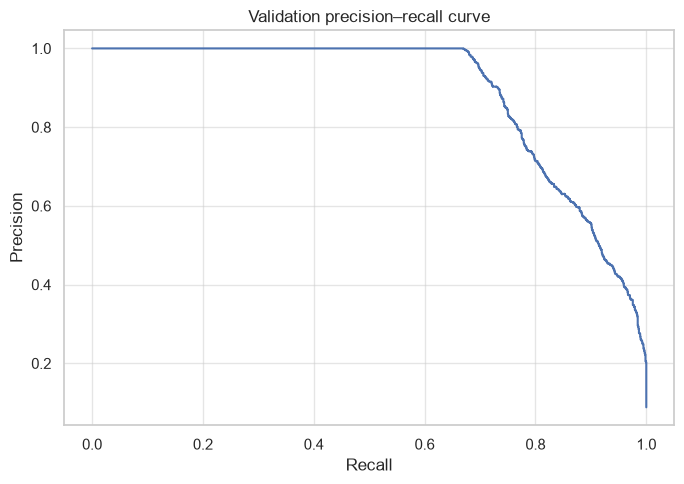

In [22]:
validation_pipeline = clone(pipelines[best_model_name])
validation_pipeline.fit(X_dev, y_dev)
val_prob = validation_pipeline.predict_proba(X_val)[:, 1]
val_precision, val_recall, val_thresholds = precision_recall_curve(y_val, val_prob)
threshold_grid = pd.DataFrame({
    "Threshold": val_thresholds,
    "Precision": val_precision[:-1],
    "Recall": val_recall[:-1],
})
eligible = threshold_grid.loc[threshold_grid["Recall"] >= RECALL_TARGET]
if eligible.empty:
    selected_threshold = 0.50
    print("Validation recall target unmet; using a research default of 0.50.")
else:
    winner = eligible.sort_values(["Precision", "Threshold"], ascending=False).iloc[0]
    selected_threshold = float(winner["Threshold"])
selected_threshold = float(np.clip(selected_threshold, 0.0, 1.0))
val_labels = (val_prob >= selected_threshold).astype(int)
print(f"Threshold selected from validation only: {selected_threshold:.4f}")
print(f"Validation recall: {recall_score(y_val, val_labels):.3f}")
print(f"Validation precision: {precision_score(y_val, val_labels, zero_division=0):.3f}")
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(val_recall, val_precision)
ax.set(xlabel="Recall", ylabel="Precision", title="Validation precision–recall curve")
plt.tight_layout(); plt.show()

## 8. Final model refit and one-time holdout evaluation

The model family and decision threshold are now frozen. We refit on the full 80% train partition, then calculate final metrics on the 20% holdout **once**. Avoid changing the model or threshold after inspecting this result. Since the original notebook already used this same dataset's holdout for development, these estimates are not equivalent to validation on a never-before-seen external dataset.

Final model: XGBoost
Frozen threshold: 0.5902


,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC (average precision),Brier score (lower is better)
0,0.9237,0.5409,0.888,0.6723,0.9779,0.8841,0.0618


              precision    recall  f1-score   support

 No diabetes       0.99      0.93      0.96     17534
    Diabetes       0.54      0.89      0.67      1696

    accuracy                           0.92     19230
   macro avg       0.76      0.91      0.81     19230
weighted avg       0.95      0.92      0.93     19230

Confusion matrix [TN FP / FN TP]:
[[16256  1278]
 [  190  1506]]


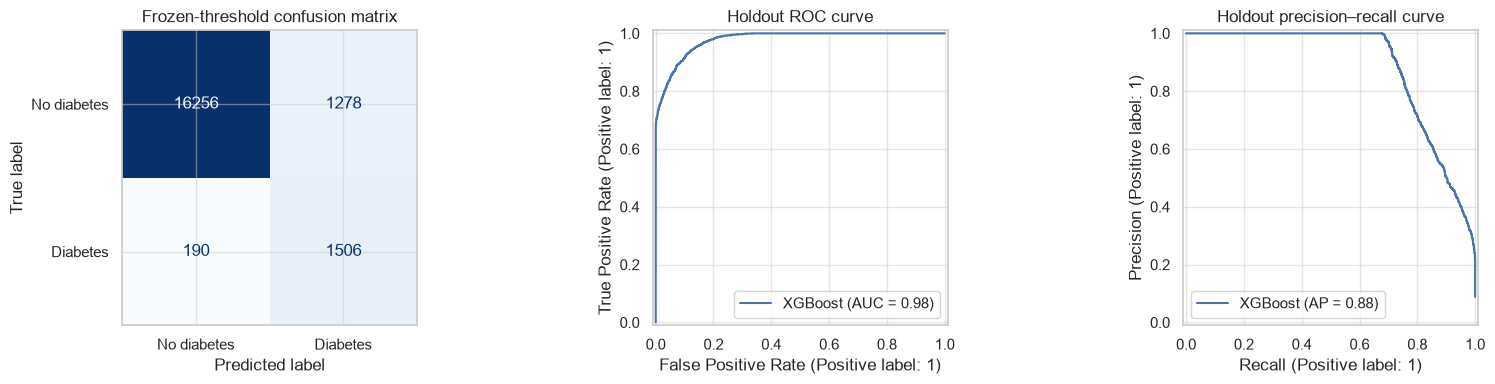

In [23]:
best_pipeline = clone(pipelines[best_model_name])
best_pipeline.fit(X_train, y_train)
test_prob = best_pipeline.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= selected_threshold).astype(int)
test_metrics = {
    "Accuracy": float(accuracy_score(y_test, test_pred)),
    "Precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "Recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "F1": float(f1_score(y_test, test_pred, zero_division=0)),
    "ROC-AUC": float(roc_auc_score(y_test, test_prob)),
    "PR-AUC (average precision)": float(average_precision_score(y_test, test_prob)),
    "Brier score (lower is better)": float(brier_score_loss(y_test, test_prob)),
}
print("Final model:", best_model_name)
print("Frozen threshold:", round(selected_threshold, 4))
display(pd.DataFrame([test_metrics]).round(4))
print(classification_report(y_test, test_pred, target_names=["No diabetes","Diabetes"], zero_division=0))
print("Confusion matrix [TN FP / FN TP]:")
print(confusion_matrix(y_test, test_pred))
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
ConfusionMatrixDisplay.from_predictions(y_test, test_pred,
    display_labels=["No diabetes", "Diabetes"], cmap="Blues", ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, test_prob, ax=axes[1], name=best_model_name)
PrecisionRecallDisplay.from_predictions(y_test, test_prob, ax=axes[2], name=best_model_name)
axes[0].set_title("Frozen-threshold confusion matrix")
axes[1].set_title("Holdout ROC curve")
axes[2].set_title("Holdout precision–recall curve")
plt.tight_layout(); plt.show()

## 9. Calibration diagnostic and subgroup analysis

ROC-AUC does not measure how well probabilities match event frequencies. The following binned reliability plot is descriptive and is **not used to recalibrate or select the model after testing**. Subgroup results are exploratory; group sizes and sample selection can make estimates unstable. A responsible healthcare application would require more complete demographic assessment and external validation.

,bin,mean_predicted,observed_frequency,count
0,0,0.009,0.001,12689
1,1,0.143,0.015,1156
2,2,0.246,0.036,775
3,3,0.350,0.054,596
4,4,0.451,0.076,603
5,5,0.548,0.100,668
6,6,0.650,0.165,707
7,7,0.749,0.208,567
8,8,0.844,0.333,291
9,9,0.998,0.991,1178


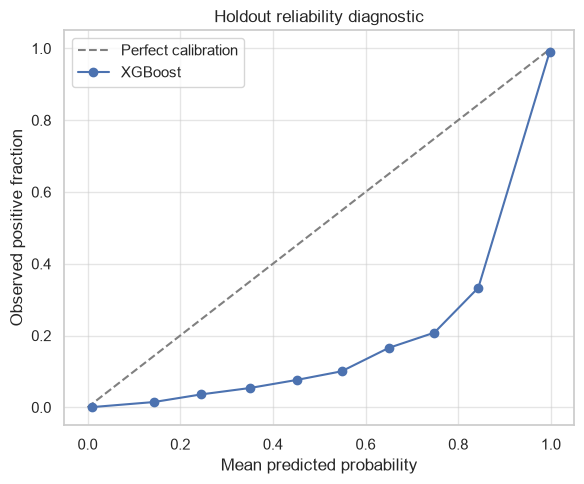

,Variable,Group,n,Positives,Recall,Precision
0,gender,Female,11344,929,0.871,0.563
1,gender,Male,7882,767,0.909,0.518
2,age group,"(50.0, 70.0]",5140,838,0.925,0.534
3,age group,"(-0.001, 30.0]",6493,72,0.653,1.000
4,age group,"(70.0, inf]",2317,481,0.938,0.500
5,age group,"(30.0, 50.0]",5280,305,0.764,0.607


In [24]:
bins = np.linspace(0, 1, 11)
bin_id = np.clip(np.digitize(test_prob, bins, right=False) - 1, 0, 9)
cal = pd.DataFrame({"bin": bin_id, "p": test_prob, "y": y_test.to_numpy()})
calibration_table = cal.groupby("bin", observed=True).agg(
    mean_predicted=("p", "mean"), observed_frequency=("y", "mean"), count=("y", "size")
).reset_index()
display(calibration_table.round(3))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0,1], [0,1], "--", color="grey", label="Perfect calibration")
ax.plot(calibration_table["mean_predicted"], calibration_table["observed_frequency"], "o-", label=best_model_name)
ax.set(xlabel="Mean predicted probability", ylabel="Observed positive fraction", title="Holdout reliability diagnostic")
ax.legend(); plt.tight_layout(); plt.show()

slice_rows = []
for group_name, groups in [("gender", X_test["gender"]),
                           ("age group", pd.cut(X_test["age"], [0,30,50,70,float("inf")], include_lowest=True))]:
    for value in groups.dropna().unique():
        mask = (groups == value).to_numpy()
        true_group = y_test.to_numpy()[mask]
        predicted_group = test_pred[mask]
        if len(true_group) < 30:
            continue
        slice_rows.append({
            "Variable": group_name, "Group": str(value), "n": int(mask.sum()),
            "Positives": int(true_group.sum()),
            "Recall": float(recall_score(true_group, predicted_group, zero_division=0)),
            "Precision": float(precision_score(true_group, predicted_group, zero_division=0)),
        })
slice_results = pd.DataFrame(slice_rows)
display(slice_results.round(3))

## 10. Explainability — model-specific feature importance and optional SHAP

Only display tree-based importances when the selected model supports them. For logistic regression, absolute coefficient sizes are presented instead. Optional SHAP uses a small **training-only** sample to avoid unnecessary use of holdout records for interpretability exploration. SHAP values describe this model, not causal effects or medical guidance.

,Feature,Importance
4,HbA1c_level,0.414362
5,blood_glucose_level,0.252498
0,age,0.113812
1,hypertension,0.066344
3,bmi,0.040352
2,heart_disease,0.036812
9,smoking_history_No Info,0.028523
7,gender_Male,0.013736
6,gender_Female,0.011547
11,smoking_history_ever,0.005629


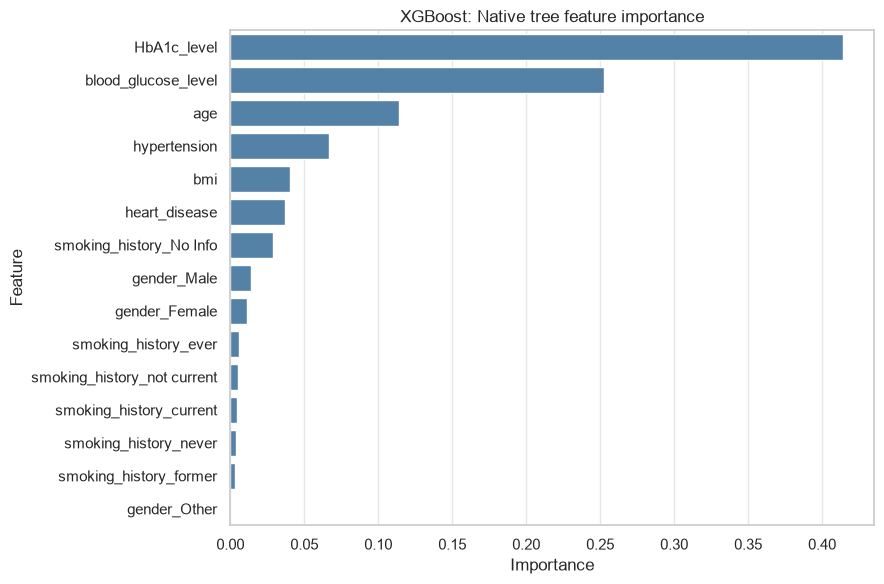

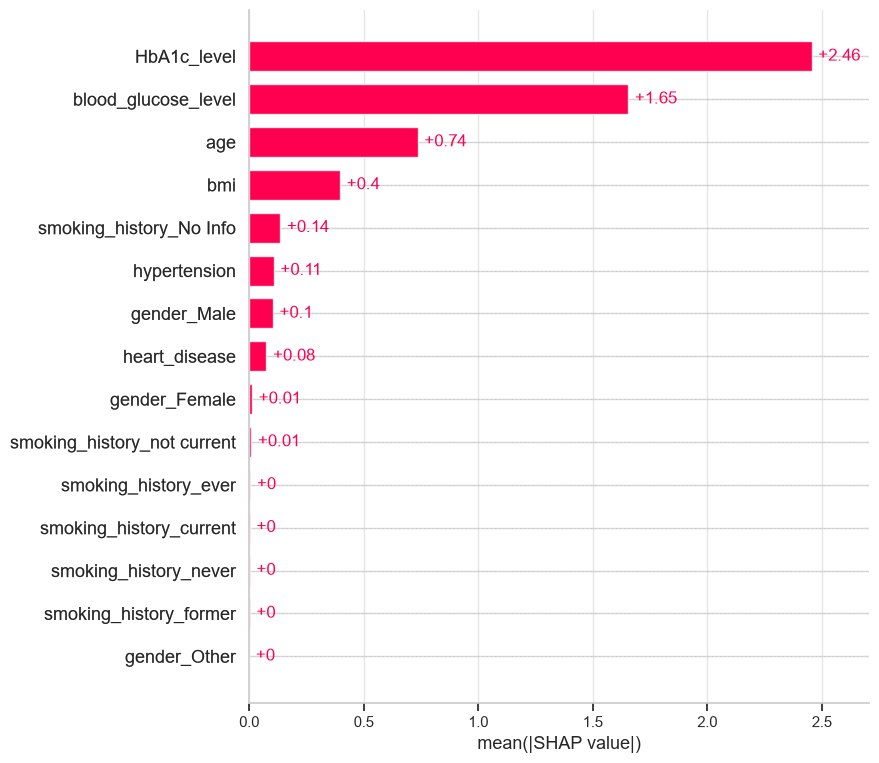

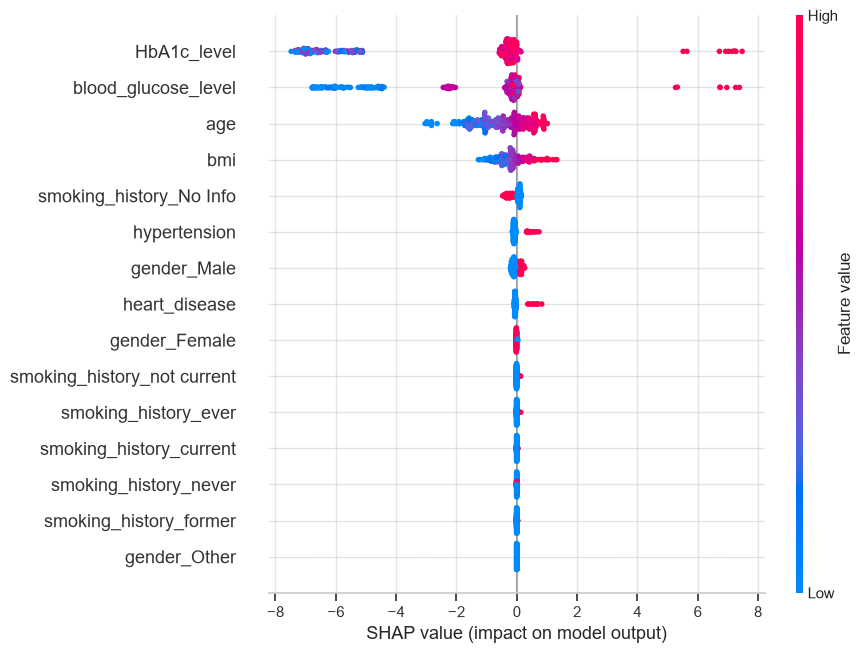

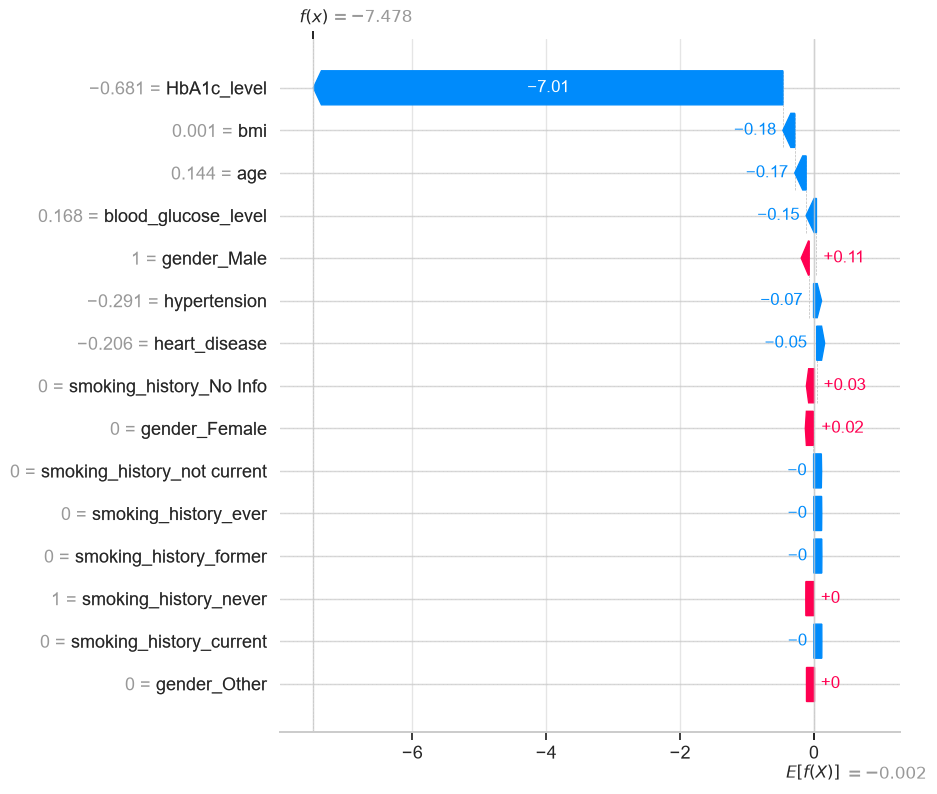

In [25]:
estimator = best_pipeline.named_steps["model"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
if hasattr(estimator, "feature_importances_"):
    importance = np.asarray(estimator.feature_importances_)
    importance_type = "Native tree feature importance"
elif hasattr(estimator, "coef_"):
    importance = np.abs(np.asarray(estimator.coef_[0]))
    importance_type = "Absolute standardized coefficient"
else:
    importance = None
if importance is not None:
    feat_table = pd.DataFrame({"Feature": feature_names, "Importance": importance})
    feat_table = feat_table.sort_values("Importance", ascending=False).head(15)
    display(feat_table)
    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(data=feat_table, x="Importance", y="Feature", color="steelblue", ax=ax)
    ax.set_title(f"{best_model_name}: {importance_type}")
    plt.tight_layout(); plt.show()

RUN_SHAP = True  # Set False if SHAP is unavailable or compute is limited.
if RUN_SHAP and hasattr(estimator, "feature_importances_"):
    try:
        import shap
        sample = X_train.sample(min(300, len(X_train)), random_state=RANDOM_STATE)
        transformed = best_pipeline.named_steps["preprocessor"].transform(sample)
        transformed_df = pd.DataFrame(transformed, columns=feature_names)
        explainer = shap.TreeExplainer(estimator)
        shap_values = explainer(transformed_df)
        if np.ndim(shap_values.values) == 3:
            shap_values = shap.Explanation(
                values=shap_values.values[:, :, 1],
                base_values=np.asarray(shap_values.base_values)[:, 1],
                data=shap_values.data, feature_names=feature_names)
        shap.plots.bar(shap_values, max_display=15)
        shap.plots.beeswarm(shap_values, max_display=15)
        shap.plots.waterfall(shap_values[0], max_display=15)
    except (ImportError, RuntimeError, ValueError, TypeError) as exc:
        print("SHAP skipped due to an environment/version issue:", str(exc))
else:
    print("SHAP skipped: not a tree estimator or RUN_SHAP=False.")

## 11. Save the fitted pipeline **and** frozen operating threshold

A pipeline's `.predict()` always uses the estimator's default threshold; for this research experiment we must save the **separately validated threshold** and apply it to `.predict_proba()` during inference. Model artifacts are Python pickle-based: load them **only from trusted sources**. Do not publish patient-level records.

In [26]:
MODEL_PATH = OUTPUT_DIR / "best_diabetes_pipeline.joblib"
METADATA_PATH = OUTPUT_DIR / "model_metadata.json"
joblib.dump(best_pipeline, MODEL_PATH)
metadata = {
    "model": best_model_name,
    "selection_metric": "development cross-validation mean ROC-AUC",
    "cv_folds": CV_FOLDS,
    "validation_recall_target_research_only": RECALL_TARGET,
    "decision_threshold": selected_threshold,
    "dataset_rows_after_cleaning": int(len(df)),
    "train_rows": int(len(X_train)),
    "holdout_rows": int(len(X_test)),
    "features": NUMERIC_FEATURES + CATEGORICAL_FEATURES,
    "test_metrics": test_metrics,
    "disclaimer": "Educational research only; not validated for clinical use",
}
METADATA_PATH.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
print("Saved model:", MODEL_PATH.resolve())
print("Saved metadata:", METADATA_PATH.resolve())

Saved model: C:\Users\User\PyCharmMiscProject\diabetes prediction model\output\best_diabetes_pipeline.joblib
Saved metadata: C:\Users\User\PyCharmMiscProject\diabetes prediction model\output\model_metadata.json


## 12. Smoke-test inference with a fictional record

The numerical output is an **algorithmic score** from a model trained on the dataset, not a diagnosis or necessarily a clinically calibrated probability. All units, allowable ranges and category values would need validation in an actual user-facing service.

In [27]:
loaded_pipeline = joblib.load(MODEL_PATH)  # Only trust artifacts created by this project.
loaded_metadata = json.loads(METADATA_PATH.read_text(encoding="utf-8"))
frozen_threshold = float(loaded_metadata["decision_threshold"])
fictional_record = pd.DataFrame([{
    "gender": "Female", "age": 52.0, "hypertension": 1,
    "heart_disease": 0, "smoking_history": "former", "bmi": 31.8,
    "HbA1c_level": 6.7, "blood_glucose_level": 180,
}])
score = float(loaded_pipeline.predict_proba(fictional_record)[0, 1])
research_class = int(score >= frozen_threshold)
assert 0 <= score <= 1
print("Fictional record only")
print(f"Algorithmic score: {score:.3f}")
print(f"Research cutoff: {frozen_threshold:.3f}")
print(f"Dataset-label classification: {research_class}")
print("Not a clinical diagnosis; this project is not validated for patient care.")

Fictional record only
Algorithmic score: 0.684
Research cutoff: 0.590
Dataset-label classification: 1
Not a clinical diagnosis; this project is not validated for patient care.


## 13. Limitations, next experiments and responsible use

- **No external clinical validation:** The dataset's collection, sampling, patient uniqueness, diagnostic labelling and representativeness need verification before clinical claims.
- **Clinical feature availability:** HbA1c and blood glucose may make this a *classification of existing diagnostic status*, not early risk prediction. A second model excluding these laboratory tests is a valuable future benchmark.
- **Data leakage beyond code:** Without patient identifiers or acquisition timestamps, repeated-patient and temporal leakage cannot be ruled out. Removing exact duplicate rows does not solve this.
- **Threshold and calibration:** The 0.90 validation sensitivity target is illustrative. The model is **not calibrated for care**, despite reporting a diagnostic Brier score and reliability plot.
- **Fairness:** Demographic slice results are descriptive; additional prospective multi-site testing is needed to evaluate equitable performance.
- **Reproducibility:** Dataset version/source/license and dependency versions should be recorded when publishing. Real-world deployment needs data contracts, authenticated services, monitoring and security reviews.
- **Original report:** Previous XGBoost metrics (96.85% accuracy, 72.88% recall) are from an *older workflow*. Do not copy them into the revised project without rerunning this notebook and updating the report.

**Next proposed milestone:** add a non-laboratory-features comparison and a reproducible CLI training script, then tests and a Streamlit demo. Never frame the current research notebook as clinical software.